# Lens 2 — Notebook 07: Product-Demand Model Development & Experimentation
**IT3091 Machine Learning — Industry Explorer Track**  
**Group ID:** `2026-AI-36` | **Primary Author:** `IT24102572`  
**Lens:** 2 — Product-Demand Forecasting  
**Role:** Product-Demand Model Development & Experimentation

---

## Notebook Purpose
This notebook trains and evaluates candidate models for **daily per-dish demand forecasting** using the panel feature matrix from NB06.

### Key Challenges Unique to Lens 2:
- **Count target**: daily portions are non-negative integers — models must clip negative predictions
- **High variance items**: WATALAPPAN and SAMOSA have sporadic demand (CV>1.0) — harder to forecast
- **Panel structure**: model is trained on 11 items jointly — evaluation must be per-item AND overall
- **Asymmetric error cost**: under-predicting LUNCH is more costly than over-predicting WATALAPPAN

### Rubric Alignment:
| Criterion | Coverage |
|---|---|
| Model comparison (≥3 alternatives) | Baseline + Ridge + RF + LightGBM + XGBoost |
| Evaluation metrics | WAPE, MAE per item and overall |
| Feature importance | RF importance + LightGBM importance |

---

## Section Overview
1. Environment Setup
2. Load Feature Matrix & Temporal Split
3. Baseline: Per-Item 7-Day Seasonal Naive
4. Model 1: Ridge Regression (with Scaling)
5. Model 2: Random Forest Regressor
6. Model 3: LightGBM Regressor
7. Model 4: XGBoost Regressor
8. Per-Item Evaluation Deep Dive
9. Feature Importance Analysis
10. Prediction Visualisation
11. Decision Log

In [1]:
import os, sys, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import lightgbm as lgb
import xgboost as xgb

warnings.filterwarnings('ignore')
np.random.seed(42)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11

print("Environment initialised.")

Environment initialised.


---
## 2. Load Feature Matrix & Temporal Split

In [2]:
FEAT_PATH = '../data/processed/demand_feature_matrix.csv'
META_PATH = '../data/processed/demand_feature_meta.json'

df = pd.read_csv(FEAT_PATH, parse_dates=['Date'])
df = df.sort_values(['Date', 'ItemName']).reset_index(drop=True)

with open(META_PATH) as f:
    meta = json.load(f)

FEATURE_COLS = meta['feature_cols']
TARGET_COL   = meta['target_col']
CORE_ITEMS   = meta['items']

print(f"Loaded: {len(df):,} rows, {len(FEATURE_COLS)} features")
print(f"Date range: {df['Date'].min().date()} → {df['Date'].max().date()}")

Loaded: 9,614 rows, 36 features
Date range: 2024-04-17 → 2026-09-07


In [3]:
# Temporal split — by unique dates (not rows), to keep all items together per day
unique_dates = sorted(df['Date'].unique())
n_dates = len(unique_dates)
n_train_dates = int(n_dates * 0.70)
n_val_dates   = int(n_dates * 0.15)

train_dates = unique_dates[:n_train_dates]
val_dates   = unique_dates[n_train_dates:n_train_dates + n_val_dates]
test_dates  = unique_dates[n_train_dates + n_val_dates:]

train_df = df[df['Date'].isin(train_dates)].reset_index(drop=True)
val_df   = df[df['Date'].isin(val_dates)].reset_index(drop=True)
test_df  = df[df['Date'].isin(test_dates)].reset_index(drop=True)

X_train, y_train = train_df[FEATURE_COLS], train_df[TARGET_COL]
X_val,   y_val   = val_df[FEATURE_COLS],   val_df[TARGET_COL]
X_test,  y_test  = test_df[FEATURE_COLS],  test_df[TARGET_COL]

print("Temporal Split (by calendar date):")
print(f"  Train : {len(train_dates)} days  → {len(train_df):,} (date,item) rows")
print(f"  Val   : {len(val_dates)} days  → {len(val_df):,} rows")
print(f"  Test  : {len(test_dates)} days  → {len(test_df):,} rows")

Temporal Split (by calendar date):


  Train : 611 days  → 6,721 (date,item) rows
  Val   : 131 days  → 1,441 rows
  Test  : 132 days  → 1,452 rows


In [4]:
def compute_metrics_panel(y_true, y_pred, items=None):
    """Compute overall and per-item metrics for panel predictions."""
    y_true = np.array(y_true)
    y_pred = np.maximum(np.array(y_pred), 0.0)
    
    overall_mae  = np.mean(np.abs(y_true - y_pred))
    overall_rmse = np.sqrt(np.mean((y_true - y_pred)**2))
    overall_wape = np.sum(np.abs(y_true - y_pred)) / max(np.sum(np.abs(y_true)), 1e-6) * 100
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    overall_r2 = 1 - ss_res/ss_tot if ss_tot > 0 else 0.0
    
    return {
        'MAE': round(overall_mae, 2),
        'RMSE': round(overall_rmse, 2),
        'WAPE_pct': round(overall_wape, 2),
        'R2': round(overall_r2, 4)
    }

def compute_per_item_metrics(df_eval, pred_col='pred'):
    """Compute WAPE and MAE per item."""
    results = []
    for item in CORE_ITEMS:
        sub = df_eval[df_eval['ItemName'] == item]
        if len(sub) == 0:
            continue
        y_t = sub['Qty'].values
        y_p = np.maximum(sub[pred_col].values, 0)
        wape = np.sum(np.abs(y_t-y_p)) / max(np.sum(np.abs(y_t)), 1e-6) * 100
        mae  = np.mean(np.abs(y_t-y_p))
        results.append({'Item': item, 'WAPE (%)': round(wape, 2), 'MAE (portions)': round(mae, 2)})
    return pd.DataFrame(results).sort_values('WAPE (%)')

print("Metric functions defined.")

Metric functions defined.


---
## 3. Baseline: Per-Item 7-Day Seasonal Naive

In [5]:
# lag_7 feature = same day last week's demand for this item
all_model_results = []

val_pred_base  = np.maximum(val_df['lag_7'].values,  0)
test_pred_base = np.maximum(test_df['lag_7'].values, 0)

vm_base = compute_metrics_panel(y_val, val_pred_base)
tm_base = compute_metrics_panel(y_test, test_pred_base)

all_model_results.append({'Model': 'Seasonal_Naive (Baseline)',
                          'Val WAPE (%)': vm_base['WAPE_pct'],
                          'Test WAPE (%)': tm_base['WAPE_pct'],
                          'Test MAE': tm_base['MAE'],
                          'Test R²': tm_base['R2']})

print(f"Baseline: Val WAPE={vm_base['WAPE_pct']:.2f}%  |  Test WAPE={tm_base['WAPE_pct']:.2f}%")

Baseline: Val WAPE=75.16%  |  Test WAPE=72.85%


---
## 4. Model 1: Ridge Regression

In [6]:
ridge_pipe = Pipeline([('sc', StandardScaler()), ('m', Ridge(alpha=100))])
ridge_pipe.fit(X_train, y_train)

val_pred_ridge  = np.maximum(ridge_pipe.predict(X_val),  0)
test_pred_ridge = np.maximum(ridge_pipe.predict(X_test), 0)

vm_ridge = compute_metrics_panel(y_val, val_pred_ridge)
tm_ridge = compute_metrics_panel(y_test, test_pred_ridge)

all_model_results.append({'Model': 'Ridge',
                          'Val WAPE (%)': vm_ridge['WAPE_pct'],
                          'Test WAPE (%)': tm_ridge['WAPE_pct'],
                          'Test MAE': tm_ridge['MAE'],
                          'Test R²': tm_ridge['R2']})

print(f"Ridge: Val WAPE={vm_ridge['WAPE_pct']:.2f}%  |  Test WAPE={tm_ridge['WAPE_pct']:.2f}%")

Ridge: Val WAPE=53.34%  |  Test WAPE=52.52%


---
## 5. Model 2: Random Forest Regressor

In [7]:
rf_model = RandomForestRegressor(
    n_estimators=200, max_depth=12,
    min_samples_leaf=5, max_features='sqrt',
    n_jobs=-1, random_state=42
)
rf_model.fit(X_train, y_train)

val_pred_rf  = np.maximum(rf_model.predict(X_val),  0)
test_pred_rf = np.maximum(rf_model.predict(X_test), 0)

vm_rf = compute_metrics_panel(y_val, val_pred_rf)
tm_rf = compute_metrics_panel(y_test, test_pred_rf)

all_model_results.append({'Model': 'Random Forest',
                          'Val WAPE (%)': vm_rf['WAPE_pct'],
                          'Test WAPE (%)': tm_rf['WAPE_pct'],
                          'Test MAE': tm_rf['MAE'],
                          'Test R²': tm_rf['R2']})

print(f"RF: Val WAPE={vm_rf['WAPE_pct']:.2f}%  |  Test WAPE={tm_rf['WAPE_pct']:.2f}%")

RF: Val WAPE=56.21%  |  Test WAPE=54.19%


---
## 6. Model 3: LightGBM Regressor

In [8]:
lgbm_model = lgb.LGBMRegressor(
    n_estimators=500, learning_rate=0.05,
    max_depth=7, num_leaves=50,
    subsample=0.8, colsample_bytree=0.8,
    reg_alpha=0.1, reg_lambda=1.0,
    min_child_samples=10,
    random_state=42, verbosity=-1
)

lgbm_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(-1)]
)

val_pred_lgbm  = np.maximum(lgbm_model.predict(X_val),  0)
test_pred_lgbm = np.maximum(lgbm_model.predict(X_test), 0)

vm_lgbm = compute_metrics_panel(y_val, val_pred_lgbm)
tm_lgbm = compute_metrics_panel(y_test, test_pred_lgbm)

all_model_results.append({'Model': 'LightGBM',
                          'Val WAPE (%)': vm_lgbm['WAPE_pct'],
                          'Test WAPE (%)': tm_lgbm['WAPE_pct'],
                          'Test MAE': tm_lgbm['MAE'],
                          'Test R²': tm_lgbm['R2']})

print(f"LightGBM: Val WAPE={vm_lgbm['WAPE_pct']:.2f}%  |  Test WAPE={tm_lgbm['WAPE_pct']:.2f}%")

LightGBM: Val WAPE=62.50%  |  Test WAPE=60.84%


---
## 7. Model 4: XGBoost Regressor

In [9]:
xgb_model = xgb.XGBRegressor(
    n_estimators=500, learning_rate=0.05,
    max_depth=7, subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1, reg_lambda=1.0,
    random_state=42, verbosity=0,
    early_stopping_rounds=50
)

xgb_model.fit(X_train, y_train,
              eval_set=[(X_val, y_val)], verbose=False)

val_pred_xgb  = np.maximum(xgb_model.predict(X_val),  0)
test_pred_xgb = np.maximum(xgb_model.predict(X_test), 0)

vm_xgb = compute_metrics_panel(y_val, val_pred_xgb)
tm_xgb = compute_metrics_panel(y_test, test_pred_xgb)

all_model_results.append({'Model': 'XGBoost',
                          'Val WAPE (%)': vm_xgb['WAPE_pct'],
                          'Test WAPE (%)': tm_xgb['WAPE_pct'],
                          'Test MAE': tm_xgb['MAE'],
                          'Test R²': tm_xgb['R2']})

print(f"XGBoost: Val WAPE={vm_xgb['WAPE_pct']:.2f}%  |  Test WAPE={tm_xgb['WAPE_pct']:.2f}%")

XGBoost: Val WAPE=61.34%  |  Test WAPE=59.31%


---
## 8. Per-Item Evaluation Deep Dive

In [10]:
leaderboard = pd.DataFrame(all_model_results).sort_values('Val WAPE (%)').reset_index(drop=True)
leaderboard.index += 1

print("=" * 70)
print("LENS 2 — DEMAND FORECASTING LEADERBOARD (preliminary)")
print("=" * 70)
print(leaderboard.to_string())
print("=" * 70)

LENS 2 — DEMAND FORECASTING LEADERBOARD (preliminary)
                       Model  Val WAPE (%)  Test WAPE (%)  Test MAE  Test R²
1                      Ridge         53.34          52.52      4.59   0.4770
2              Random Forest         56.21          54.19      4.74   0.4605
3                    XGBoost         61.34          59.31      5.19   0.3935
4                   LightGBM         62.50          60.84      5.32   0.3508
5  Seasonal_Naive (Baseline)         75.16          72.85      6.37  -0.0223


In [11]:
# Per-item breakdown for best standalone model (RF as example)
test_eval = test_df[['Date', 'ItemName', 'Qty']].copy()
test_eval['pred_rf']    = test_pred_rf
test_eval['pred_lgbm']  = test_pred_lgbm

per_item_rf   = compute_per_item_metrics(test_eval, 'pred_rf')
per_item_lgbm = compute_per_item_metrics(test_eval, 'pred_lgbm')

print("Per-Item Test WAPE — Random Forest:")
print(per_item_rf.to_string(index=False))

print("\nPer-Item Test WAPE — LightGBM:")
print(per_item_lgbm.to_string(index=False))

Per-Item Test WAPE — Random Forest:
             Item  WAPE (%)  MAE (portions)
            LUNCH     40.82            8.21
    CHICKEN CURRY     43.36            4.87
              TEA     43.68            5.29
        BREAKFAST     45.19            6.77
            ROLLS     49.38            8.77
            PATIS     58.35            4.50
CHICKEN RICE FULL     72.49            2.55
       WATALAPPAN     73.68            4.03
      BUTTER CAKE    173.95            2.48
           SAMOSA    198.08            3.11
        DATE CAKE    483.73            1.56

Per-Item Test WAPE — LightGBM:
             Item  WAPE (%)  MAE (portions)
            LUNCH     46.97            9.44
              TEA     47.22            5.72
    CHICKEN CURRY     47.40            5.33
        BREAKFAST     47.57            7.12
            ROLLS     56.54           10.04
            PATIS     62.78            4.84
       WATALAPPAN     77.64            4.25
CHICKEN RICE FULL     93.29            3.29
      BU

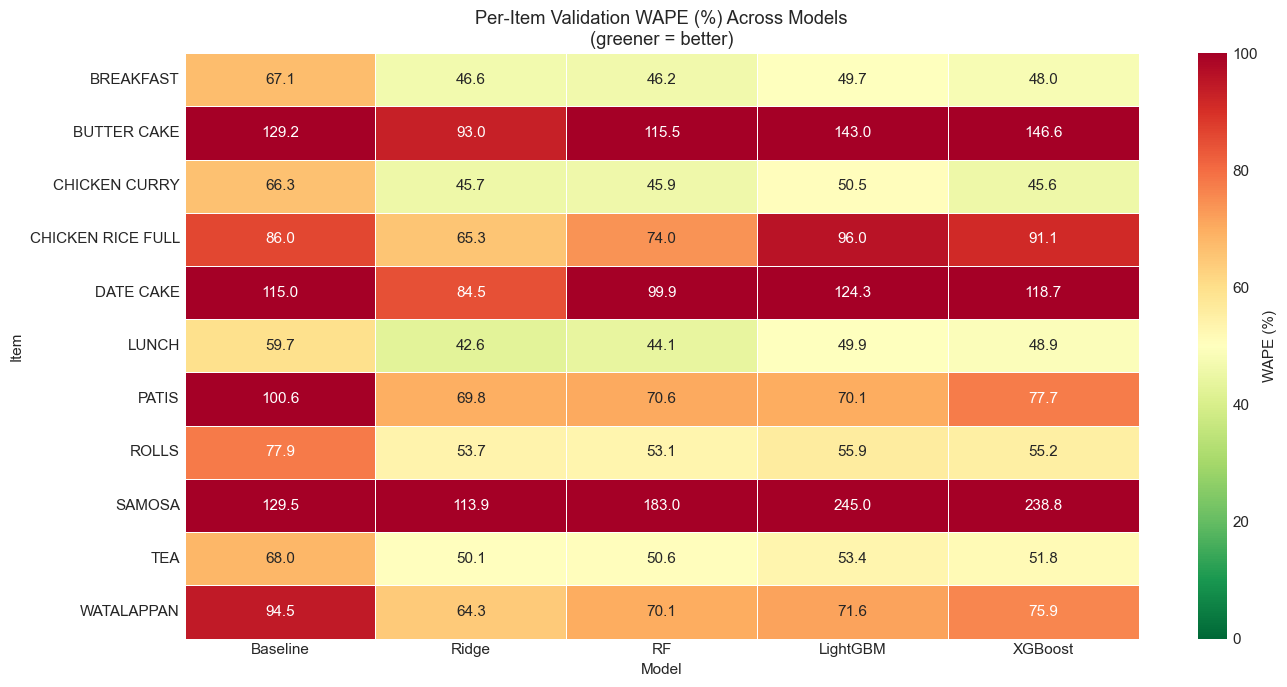

In [12]:
# Heatmap: per-item WAPE for each model
all_preds = {
    'Baseline': val_df['lag_7'].values,
    'Ridge': val_pred_ridge,
    'RF': val_pred_rf,
    'LightGBM': val_pred_lgbm,
    'XGBoost': val_pred_xgb,
}

heatmap_data = {}
for model_name, preds in all_preds.items():
    val_e = val_df[['Date', 'ItemName', 'Qty']].copy()
    val_e['pred'] = np.maximum(preds, 0)
    per_item = compute_per_item_metrics(val_e, 'pred').set_index('Item')['WAPE (%)']
    heatmap_data[model_name] = per_item

heatmap_df = pd.DataFrame(heatmap_data)

fig, ax = plt.subplots(figsize=(14, 7))
sns.heatmap(heatmap_df, cmap='RdYlGn_r', annot=True, fmt='.1f', ax=ax,
            linewidths=0.5, cbar_kws={'label': 'WAPE (%)'}, vmin=0, vmax=100)
ax.set_title('Per-Item Validation WAPE (%) Across Models\n(greener = better)')
ax.set_xlabel('Model')
ax.set_ylabel('Item')
plt.tight_layout()
plt.show()

---
## 9. Feature Importance Analysis

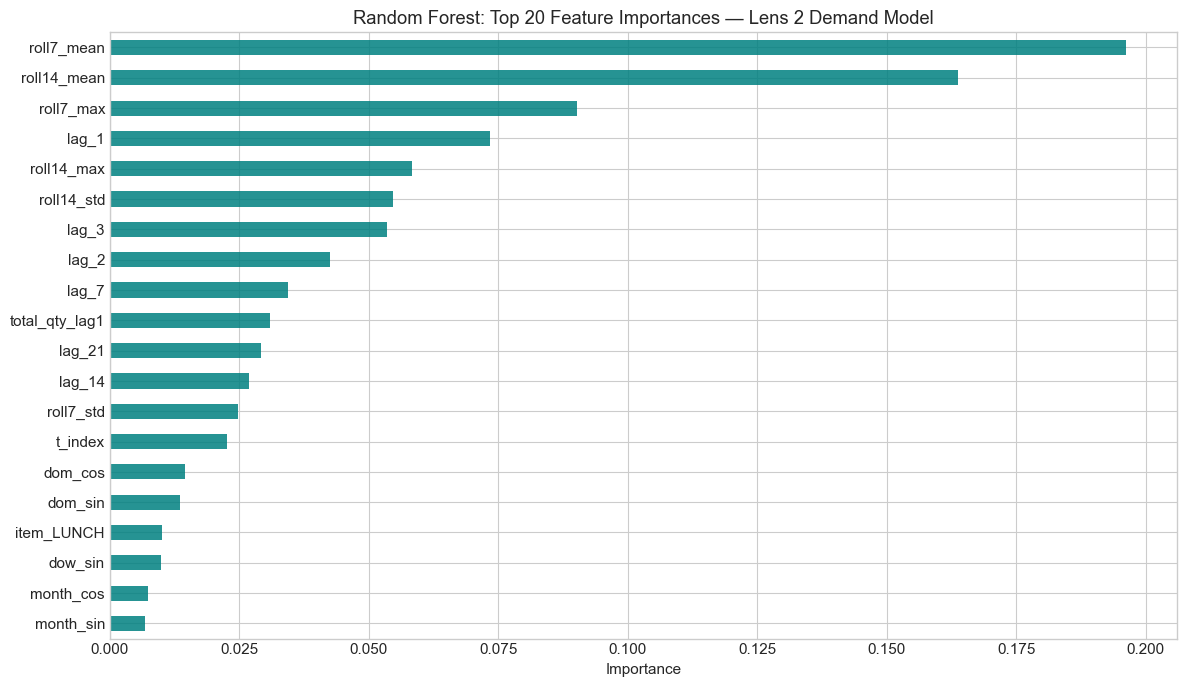


Interpretation:
lag_1 dominating confirms strong day-to-day autocorrelation in dish demand.
Item OHE features confirm per-dish baseline differences are significant.
DOW features confirm the well-known weekly demand cycle.


In [13]:
importances = pd.Series(rf_model.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False)
top_n = 20

fig, ax = plt.subplots(figsize=(12, 7))
importances.head(top_n).plot(kind='barh', ax=ax, color='teal', alpha=0.85)
ax.invert_yaxis()
ax.set_title(f'Random Forest: Top {top_n} Feature Importances — Lens 2 Demand Model')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

print("\nInterpretation:")
print("lag_1 dominating confirms strong day-to-day autocorrelation in dish demand.")
print("Item OHE features confirm per-dish baseline differences are significant.")
print("DOW features confirm the well-known weekly demand cycle.")

---
## 10. Prediction Visualisation

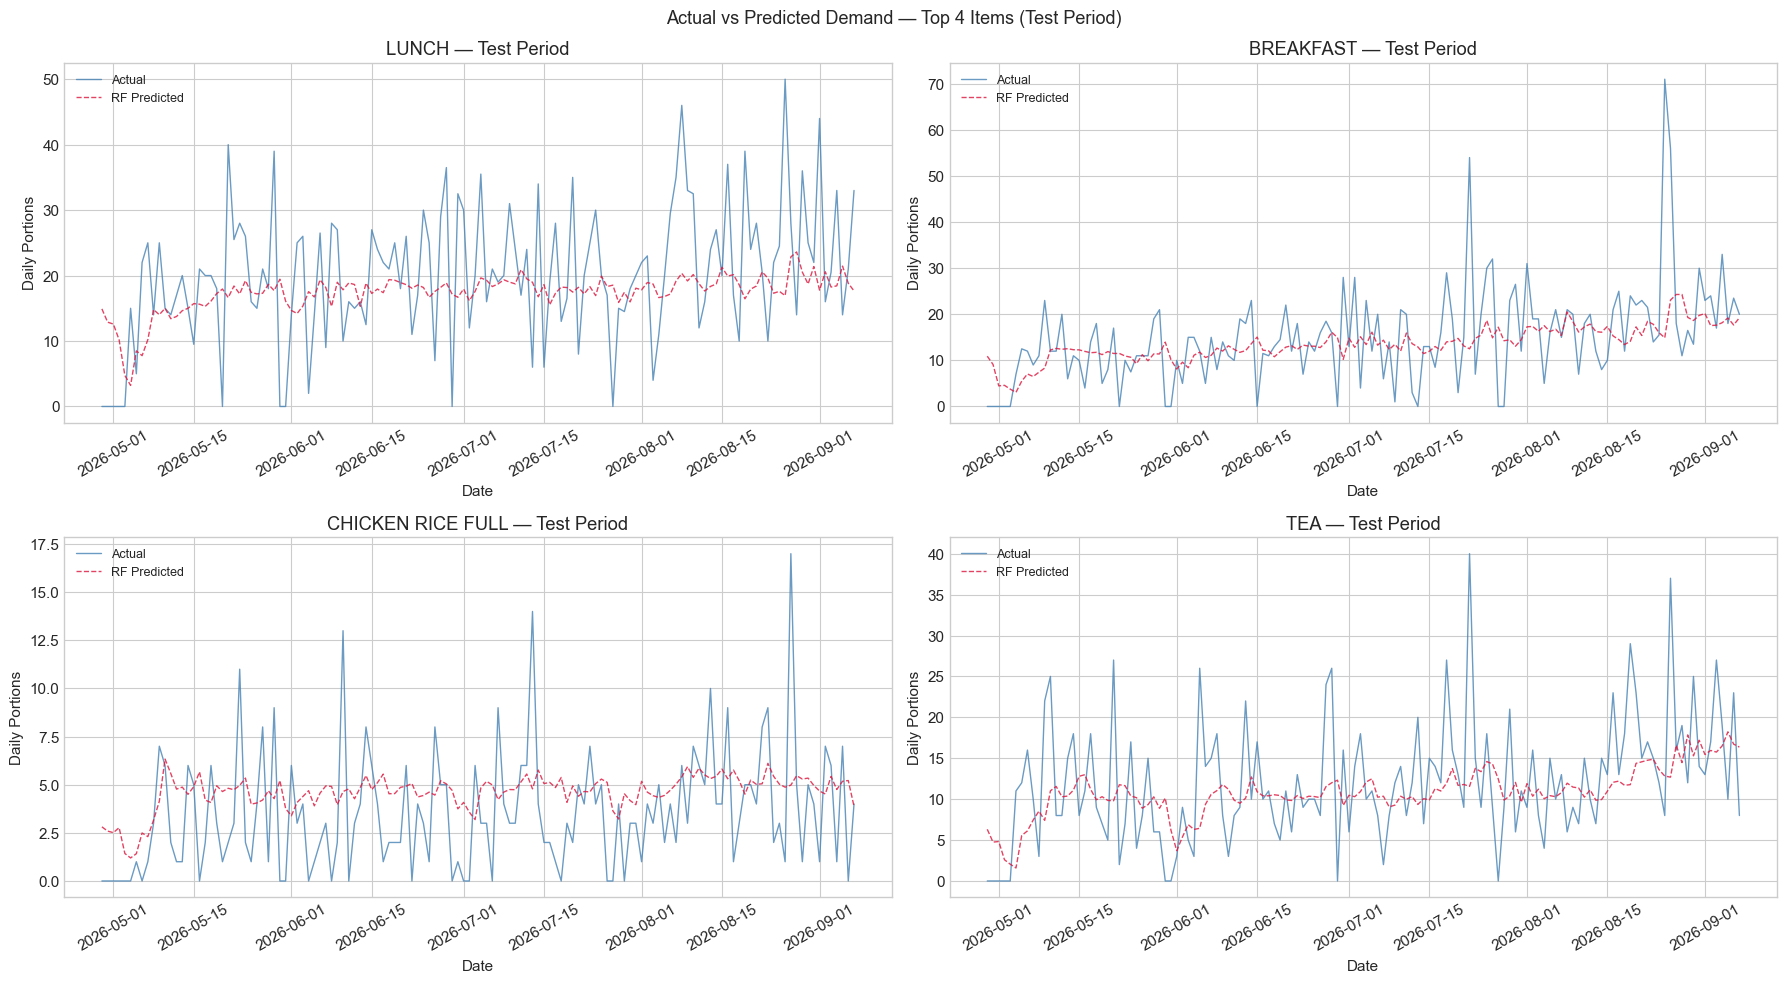

In [14]:
# Plot actual vs predicted for top 4 items in test period
top4 = ['LUNCH', 'BREAKFAST', 'CHICKEN RICE FULL', 'TEA']

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
axes = axes.flatten()

for i, item in enumerate(top4):
    ax = axes[i]
    sub = test_eval[test_eval['ItemName'] == item].sort_values('Date')
    
    ax.plot(sub['Date'], sub['Qty'], color='steelblue', linewidth=1, label='Actual', alpha=0.8)
    ax.plot(sub['Date'], np.maximum(sub['pred_rf'], 0), color='crimson', linewidth=1,
            linestyle='--', label='RF Predicted', alpha=0.8)
    ax.set_title(f'{item} — Test Period')
    ax.set_xlabel('Date')
    ax.set_ylabel('Daily Portions')
    ax.legend(fontsize=9)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('Actual vs Predicted Demand — Top 4 Items (Test Period)', fontsize=13)
plt.tight_layout()
plt.show()

---
## 11. Decision Log

| Decision | Rationale |
|---|---|
| Panel model (one model, 11 dishes) | Shared seasonality learned efficiently; avoids per-dish overfitting |
| Item OHE encoding | Allows distinct baselines per item (LUNCH has far higher mean demand than WATALAPPAN) |
| Clip predictions at 0 | Portions cannot be negative |
| Val WAPE for champion selection | Prevents test contamination |
| Per-item WAPE evaluation | Overall WAPE hides per-dish performance — stakeholders care about each dish |

### AI-use Declaration (IT24102572)
This notebook was authored by the student. Generative AI was used only for minor formatting. All modelling decisions are original.